# Milestone 1 — Analyse exploratoire des données

**But :** comprendre les 3 sources avant de consolider les livraisons, et choisir une stratégie pour chaque problème trouvé.

Chaque point suit le même schéma : **cellule de contrôle → constat → stratégie → pourquoi**.
Les points marqués **À valider (prof)** ont plusieurs options possibles : la décision reste ouverte.

Colonnes `transmission_date` et `version_date` : ignorées (consigne du prof).

In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
DATA_DIR = Path("../docs")

CAMION_KG = 24_500  # capacité poids d'un camion
CAMION_M3 = 110.4  # capacité volume d'un camion

schedule = pd.read_csv(
    DATA_DIR / "released_schedule.csv", encoding="utf-8-sig", parse_dates=["date"]
)
schedule = schedule.drop(columns=["transmission_date", "version_date"])
distances = pd.read_csv(DATA_DIR / "distances.csv", encoding="utf-8-sig")
rates = pd.read_csv(DATA_DIR / "rate_sheet.csv", dtype={"km_up_to": str}).set_index(
    "km_up_to"
)

print("released_schedule :", schedule.shape)
print("distances         :", distances.shape)
print("rate_sheet        :", rates.shape)
schedule.head()

released_schedule : (5728, 8)
distances         : (156, 2)
rate_sheet        : (14, 15)


,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume
0,2026-11-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116
1,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116
2,2026-11-12,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.0,0.0,0.4116
3,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116
4,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5000.0,92.6,0.4116


In [6]:
# Valeurs manquantes et nombre de valeurs distinctes par colonne
pd.DataFrame({"manquants": schedule.isna().sum(), "distinctes": schedule.nunique()})

,manquants,distinctes
date,0,35
supplier_id,0,94
material,0,1229
plant,0,4
unloading_point,0,51
schedule_quantity,0,399
weight,169,1746
volume,147,60


## 1. Lignes sans besoin (quantité = 0)

In [7]:
import logging

logger = logging.getLogger(__name__)

quantity_state = np.where(qty > 0, "quantity > 0", "quantity = 0")

weight_state = np.select(
    [schedule["weight"].isna(), schedule["weight"] == 0],
    ["weight missing", "weight = 0"],
    default="weight > 0",
)

volume_state = np.select(
    [schedule["volume"].isna(), schedule["volume"] == 0],
    ["volume missing", "volume = 0"],
    default="volume > 0",
)

logger.info("Negative quantities: %d", (qty < 0).sum())

pd.concat(
    {
        "weight": pd.crosstab(quantity_state, weight_state, margins=True),
        "volume": pd.crosstab(quantity_state, volume_state, margins=True),
    },
    axis=1,
).rename_axis(index="quantity")

weight                                     volume                     
col_0        weight = 0 weight > 0 weight missing   All volume > 0 volume missing   All
quantity                                                                               
quantity = 0        929          0             30   959        931             28   959
quantity > 0          0       4630            139  4769       4650            119  4769
All                 929       4630            169  5728       5581            147  5728

**Constat :** 959 lignes à quantité 0, aucune quantité négative.
Parmi les lignes à 0 : 929 ont un poids 0 et 30 n'ont pas de poids ; aucune n'a un poids positif.
Parmi les 4 769 lignes avec besoin : 139 n'ont pas de poids (traitées au point 5).

**Stratégie :** ne garder que les lignes avec quantité > 0.
**Pourquoi :** 0 = « pas de besoin » (dictionnaire du cours) ; il n'y a rien à transporter.

## 2. Doublons

In [8]:
cle = ["date", "supplier_id", "material", "plant", "unloading_point"]
print("lignes identiques           :", schedule.duplicated().sum())
print("doublons sur la clé         :", schedule.duplicated(cle).sum())
print(
    "fournisseurs en double (distances) :", distances["supplier_id"].duplicated().sum()
)

lignes identiques           : 0
doublons sur la clé         : 0
fournisseurs en double (distances) : 0


**Constat :** aucun doublon. **Stratégie :** aucune action.

## 3. Calendrier des besoins

In [9]:
besoins = schedule[schedule["schedule_quantity"] > 0]

# Poids à livrer (tonnes) par jour et par usine ; 0 = aucun besoin, ou moins de 50 kg (arrondi)
par_usine = besoins.pivot_table(
    index="date", columns="plant", values="weight", aggfunc="sum"
)
par_usine = (par_usine / 1000).round(1).fillna(0)
par_usine["total"] = par_usine.sum(axis=1)
par_usine["jour"] = par_usine.index.day_name()
par_usine

plant,PLT_001,PLT_002,PLT_003,PLT_004,total,jour
date,,,,,,
2026-11-09,5.1,13.8,1.1,34.7,54.7,Monday
2026-11-10,11.0,13.3,7.8,10.5,42.6,Tuesday
2026-11-11,15.3,10.3,2.1,53.4,81.1,Wednesday
2026-11-12,13.0,26.1,15.5,28.1,82.7,Thursday
2026-11-13,10.6,2.7,2.6,11.9,27.8,Friday
2026-11-16,11.0,3.8,2.1,30.6,47.5,Monday
2026-11-17,4.4,6.9,27.4,14.8,53.5,Tuesday
2026-11-18,20.2,0.0,2.0,33.9,56.1,Wednesday
2026-11-19,14.6,2.3,13.2,22.0,52.1,Thursday


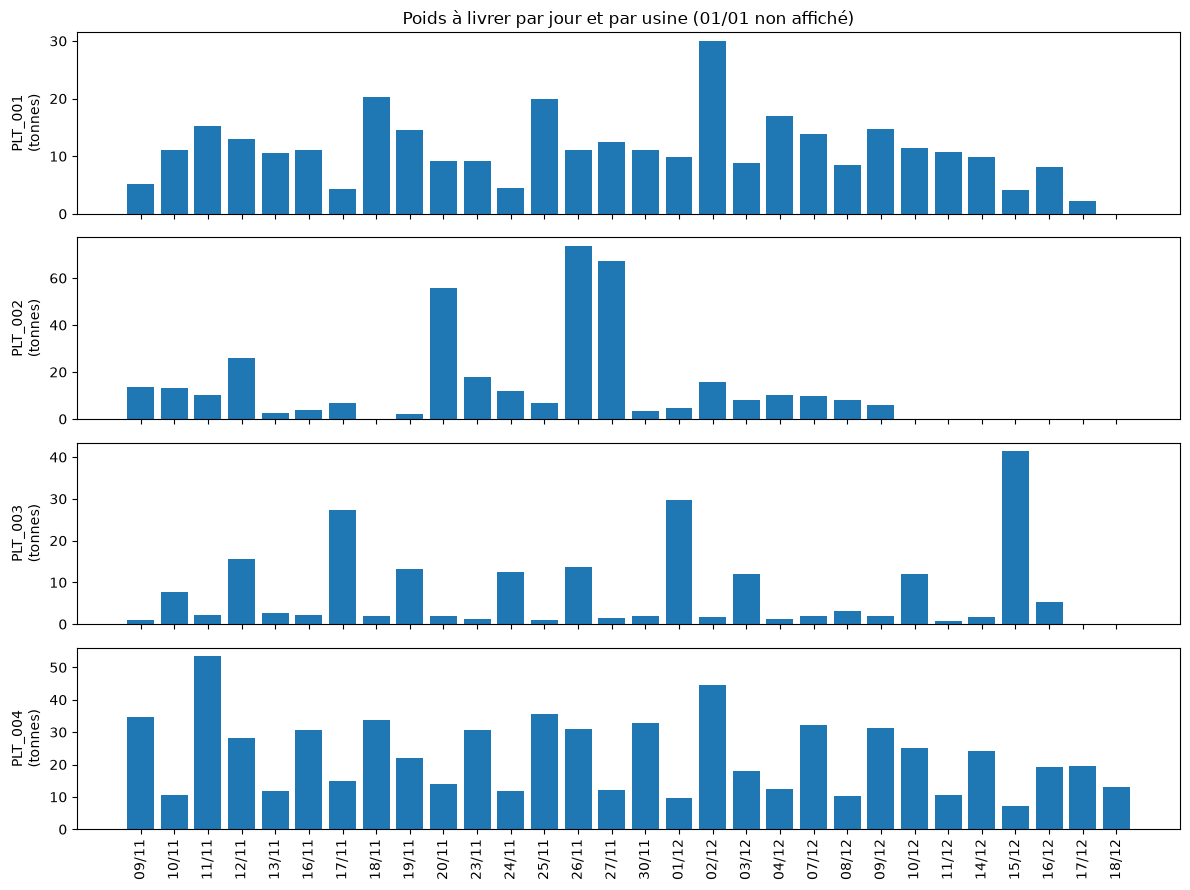

In [10]:
# Un graphique par usine (01/01 retiré pour garder une échelle lisible)
usines = ["PLT_001", "PLT_002", "PLT_003", "PLT_004"]
a_tracer = par_usine.drop(pd.Timestamp("2027-01-01"))[usines]

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, usine in zip(axes, usines):
    ax.bar(a_tracer.index.strftime("%d/%m"), a_tracer[usine])
    ax.set_ylabel(f"{usine}\n(tonnes)")
axes[0].set_title("Poids à livrer par jour et par usine (01/01 non affiché)")
axes[-1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

In [11]:
print("besoins un samedi ou dimanche :", (besoins["date"].dt.dayofweek >= 5).sum())

# Dates présentes dans le fichier mais sans aucun besoin
sans_besoin = sorted(set(schedule["date"]) - set(besoins["date"]))
print("dates sans aucun besoin :", [d.strftime("%d/%m") for d in sans_besoin])
print("lignes à ces dates      :", schedule["date"].isin(sans_besoin).sum())

besoins un samedi ou dimanche : 0
dates sans aucun besoin : ['22/12', '23/12', '28/12', '30/12']
lignes à ces dates      : 6


C:\Users\houeg\AppData\Local\Temp\ipykernel_34968\548602702.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  print("besoins un samedi ou dimanche :", (besoins["date"].dt.dayofweek >= 5).sum())


**Constat :** La charge diffère selon l'usine : PLT_001 et PLT_004 reçoivent tous les jours ; PLT_003 a ses pics les mardis et jeudis, avec un très gros pic un mardi sur deux (17/11, 01/12, 15/12) ; PLT_002 a de gros pics les 20/11, 26/11 et 27/11.

**Conséquence :** comparer les usines (nombre de livraisons, coût) sur leur propre horizon, et faire le lissage usine par usine.

### 3.1 Vue par couple fournisseur × usine
C'est l'unité de l'optimisation : on veut réduire le nombre de fois où un fournisseur livre une usine.
Aujourd'hui, une livraison = un couple × un jour de besoin. Le 01/01 est laissé de côté ici.

In [12]:
journalier = besoins[besoins["date"] < "2027-01-01"]

# Une ligne par livraison actuelle (couple x jour)
livraisons = (
    journalier.groupby(["supplier_id", "plant", "date"])[["weight", "volume"]]
    .sum()
    .reset_index()
)
livraisons["semaine"] = livraisons["date"].dt.to_period("W")

couples = (
    livraisons.groupby(["supplier_id", "plant"])
    .agg(
        livraisons=("date", "size"),
        semaines_actives=("semaine", "nunique"),
        poids_median_kg=("weight", "median"),
    )
    .round({"poids_median_kg": 0})
)
# Fréquence actuelle = livraisons par semaine active, arrondie à l'entier le plus proche
couples["livraisons_par_semaine"] = (
    (couples["livraisons"] / couples["semaines_actives"]).round().astype(int)
)

print("couples avec au moins un besoin :", len(couples))
print("livraisons actuelles            :", len(livraisons))
couples.sort_values("livraisons", ascending=False).head(10)

couples avec au moins un besoin : 180
livraisons actuelles            : 1665


,,livraisons,semaines_actives,poids_median_kg,livraisons_par_semaine
supplier_id,plant,,,,
SUP_00011,PLT_004,30,6,247.0,5
SUP_00145,PLT_004,30,6,512.0,5
SUP_00149,PLT_004,30,6,752.0,5
SUP_00085,PLT_004,30,6,2431.0,5
SUP_00080,PLT_004,29,6,882.0,5
SUP_00107,PLT_001,29,6,210.0,5
SUP_00118,PLT_001,29,6,508.0,5
SUP_00091,PLT_004,28,6,217.0,5
SUP_00087,PLT_004,28,6,612.0,5


In [13]:
# Combien de couples par fréquence actuelle ?
couples["livraisons_par_semaine"].value_counts().sort_index().rename_axis(
    "livraisons / semaine"
).rename("couples").to_frame()

,couples
livraisons / semaine,
1,76
2,60
3,18
4,16
5,10


In [14]:
# Combien de semaines (sur 6) chaque couple a-t-il au moins un besoin ?
couples["semaines_actives"].value_counts().sort_index().rename_axis(
    "semaines actives"
).rename("couples").to_frame()

,couples
semaines actives,
1,20
2,24
3,25
4,24
5,30
6,57


In [15]:
# Si chaque couple n'était livré qu'une fois par semaine : poids d'un envoi
poids_semaine = livraisons.groupby(["supplier_id", "plant", "semaine"])["weight"].sum()
print(
    "poids médian d'une semaine pour un couple :", round(poids_semaine.median()), "kg"
)
print(
    "semaines-couple > 24,5 t (plus d'un camion) :",
    (poids_semaine > CAMION_KG).sum(),
    "/",
    len(poids_semaine),
)
print(
    "couples avec une seule livraison sur toute la période :",
    (couples["livraisons"] == 1).sum(),
)

poids médian d'une semaine pour un couple : 561 kg
semaines-couple > 24,5 t (plus d'un camion) : 12 / 731
couples avec une seule livraison sur toute la période : 18


**Constat :**
* 180 couples ont au moins un besoin (le cours annonce 185 : ce chiffre compte aussi les couples sans aucun besoin).
* 136 couples sont déjà livrés 1 ou 2 fois par semaine ; le gain se concentre sur les 44 couples livrés 3 à 5 fois.
* Seulement 57 couples ont un besoin chacune des 6 semaines ; 18 couples n'ont qu'une seule livraison sur toute la période.
* Le poids d'une semaine pour un couple est de 561 kg en médiane ; seules 12 semaines-couple sur 731 dépassent un camion.

**Conséquence :** la contrainte « anticipation ≤ 7 jours » limitera plus souvent que la capacité du camion.

### 3.2 Que contient le 01/01/2027 ?

In [16]:
jour_an = besoins[besoins["date"] == "2027-01-01"]
avant = besoins[besoins["date"] < "2027-01-01"]
groupe = ["supplier_id", "material", "plant", "unloading_point"]

# Ces materials sont-ils aussi demandés pendant les 6 semaines ?
deja_vus = jour_an.set_index(groupe).index.isin(avant.set_index(groupe).index)
print("lignes du 01/01                        :", len(jour_an))
print("  material aussi présent avant le 18/12 :", deja_vus.sum())
print("  material jamais vu avant              :", (~deja_vus).sum())

# Quantité du 01/01 comparée à la quantité moyenne d'un jour normal (même material)
moyenne_jour = (
    avant.groupby(groupe)["schedule_quantity"].mean().rename("qty_moyenne_jour")
)
comparaison = jour_an.join(moyenne_jour, on=groupe).dropna(subset=["qty_moyenne_jour"])
ratio = comparaison["schedule_quantity"] / comparaison["qty_moyenne_jour"]
print("\nquantité 01/01 / quantité moyenne d'un jour :")
ratio.describe().round(1)

lignes du 01/01                        : 379
  material aussi présent avant le 18/12 : 324
  material jamais vu avant              : 55

quantité 01/01 / quantité moyenne d'un jour :


count    324.0
mean       4.6
std       15.6
min        0.3
25%        1.0
50%        2.0
75%        4.0
max      209.3
dtype: float64

In [17]:
# Impact du 01/01 sur les chiffres clés du cours (livraison = fournisseur x usine x jour)
def chiffres_cles(df):
    livr = df.groupby(["supplier_id", "plant", "date"])[["weight", "volume"]].sum()
    return pd.Series(
        {
            "livraisons": len(livr),
            "poids médian (kg)": round(livr["weight"].median()),
            "volume médian (m3)": round(livr["volume"].median(), 2),
            "remplissage médian (%)": round(
                livr["weight"].median() / CAMION_KG * 100, 2
            ),
        }
    )


pd.DataFrame({"avec 01/01": chiffres_cles(besoins), "sans 01/01": chiffres_cles(avant)})

,avec 01/01,sans 01/01
livraisons,1731.00,1665.00
poids médian (kg),316.00,304.00
volume médian (m3),1.14,1.05
remplissage médian (%),1.29,1.24


**Constat :** le 01/01 n'est pas un vrai jour de livraison. Il regroupe les besoins **après** l'horizon journalier :
quantités en général plusieurs fois supérieures à un jour normal, et 55 lignes de materials jamais vus avant.
Les chiffres du cours (1 731 livraisons, 316 kg) incluent ce jour.

**Stratégie — À valider :**
* **Option A (proposée) : exclure le 01/01 de la consolidation** et le garder à part.
  Pourquoi : jour férié, dates réelles des besoins inconnues, il fausserait le remplissage et le lissage d'une semaine.
* Option B : le garder comme un jour normal (cohérent avec les chiffres du cours).

## 4. Poids : comment il varie avec la quantité
`weight` est le poids total de la ligne (pour toute la quantité). On vérifie s'il est proportionnel à la quantité.

In [18]:
exemple = besoins[
    (besoins["material"] == "MAT_001223") & (besoins["plant"] == "PLT_004")
]
exemple = exemple[["date", "schedule_quantity", "weight", "volume"]].sort_values(
    "schedule_quantity"
)
exemple["poids_par_piece"] = (exemple["weight"] / exemple["schedule_quantity"]).round(2)
exemple

,date,schedule_quantity,weight,volume,poids_par_piece
1558,2026-11-19,1.0,142.8,1.2,142.80
1561,2026-12-02,1.0,142.8,1.2,142.80
1560,2026-12-01,1.0,142.8,1.2,142.80
1559,2026-11-20,1.0,142.8,1.2,142.80
1562,2026-12-03,1.0,142.8,1.2,142.80
1571,2026-12-17,1.0,142.8,1.2,142.80
1569,2026-12-15,1.0,142.8,1.2,142.80
1565,2026-12-09,1.0,142.8,1.2,142.80
1557,2026-11-18,2.0,143.4,1.2,71.70
1567,2026-12-11,2.0,143.4,1.2,71.70


**Constat sur l'exemple :** 1 pièce = 142,8 kg, 2 pièces = 143,4 kg, 7 pièces = 146,4 kg.
Le poids = **partie fixe** (~142,2 kg, probablement l'emballage) **+ 0,6 kg par pièce**. Il n'est pas proportionnel.
On vérifie sur tout le fichier : pour chaque fournisseur × material × usine, on ajuste une droite `poids = fixe + unitaire × quantité`.

In [19]:
resultats = []
for cle_groupe, g in avant.dropna(subset=["weight"]).groupby(
    ["supplier_id", "material", "plant"]
):
    if g["schedule_quantity"].nunique() < 2:  # il faut au moins 2 quantités différentes
        continue
    unitaire, fixe = np.polyfit(g["schedule_quantity"], g["weight"], 1)
    ecart = (g["weight"] - (fixe + unitaire * g["schedule_quantity"])).abs().max() / g[
        "weight"
    ].mean()
    resultats.append({"partie_fixe_kg": fixe, "ecart_max": ecart})
resultats = pd.DataFrame(resultats)

print("groupes testés                     :", len(resultats))
print(
    "droite exacte (écart < 1 %)        :",
    f"{(resultats['ecart_max'] < 0.01).mean():.0%}",
)
print(
    "sans partie fixe (|fixe| < 1 kg)   :",
    f"{(resultats['partie_fixe_kg'].abs() < 1).mean():.0%}",
)
print(
    "partie fixe > 50 kg                :",
    f"{(resultats['partie_fixe_kg'] > 50).mean():.0%}",
)

groupes testés                     : 327
droite exacte (écart < 1 %)        : 89%
sans partie fixe (|fixe| < 1 kg)   : 52%
partie fixe > 50 kg                : 32%


**Constat :** le modèle « partie fixe + partie par pièce » explique 89 % des groupes.
Pour environ la moitié, il n'y a pas de partie fixe (poids proportionnel) ; pour d'autres la partie fixe dépasse 50 kg.

**Stratégie :** utiliser le poids fourni tel quel.
**Pourquoi :** c'est le poids réel à charger. Mais attention : on **ne peut pas** recalculer un poids par une simple règle de trois (voir point 5).

## 5. Poids et volumes manquants

In [20]:
manque_poids = besoins["weight"].isna()
manque_volume = besoins["volume"].isna()
print("lignes avec besoin            :", len(besoins))
print(
    "poids manquant                :",
    manque_poids.sum(),
    f"({manque_poids.mean():.1%})",
)
print("volume manquant               :", manque_volume.sum())
print("volume manquant sans poids manquant :", (manque_volume & ~manque_poids).sum())

lignes avec besoin            : 4769
poids manquant                : 139 (2.9%)
volume manquant               : 119
volume manquant sans poids manquant : 0


In [21]:
# Répartition par couple fournisseur x usine
par_couple = besoins.groupby(["supplier_id", "plant"])["weight"].agg(
    lignes="size", poids_manquants=lambda x: x.isna().sum()
)
par_couple = par_couple[par_couple["poids_manquants"] > 0]
par_couple["%"] = (par_couple["poids_manquants"] / par_couple["lignes"] * 100).round()
par_couple.sort_values("poids_manquants", ascending=False)

lignes  poids_manquants      %
supplier_id plant                                  
SUP_00129   PLT_003      69               24   35.0
            PLT_001      32               19   59.0
SUP_00001   PLT_004      26               17   65.0
SUP_00117   PLT_002      21               12   57.0
SUP_00153   PLT_004      11               11  100.0
SUP_00046   PLT_002      19                6   32.0
SUP_00107   PLT_002      40                5   12.0
SUP_00145   PLT_002      83                5    6.0
SUP_00005   PLT_001      11                4   36.0
SUP_00032   PLT_002      15                3   20.0
SUP_00087   PLT_002       9                3   33.0
SUP_00018   PLT_002       3                3  100.0
SUP_00133   PLT_002       3                3  100.0
SUP_00077   PLT_002       3                3  100.0
SUP_00135   PLT_004       9                3   33.0
SUP_00102   PLT_003      14                2   14.0
SUP_00019   PLT_002      32                2    6.0
SUP_00108   PLT_001       2                2  100.0
SUP_00127   PLT_002       2                2  100.0
SUP_00054   PLT_002       2                2  100.0
SUP_00085   PLT_003      17                1    6.0
SUP_00080   PLT_002     102                1    1.0
SUP_00074   PLT_003      27                1    4.0
SUP_00091   PLT_001     113                1    1.0
SUP_00112   PLT_004      11                1    9.0
SUP_00109   PLT_002       6                1   17.0
SUP_00097   PLT_002      97                1    1.0
SUP_00144   PLT_001      67                1    1.0

In [22]:
# Peut-on retrouver le poids à partir d'autres lignes ?
connus = besoins.dropna(subset=["weight"])
a_completer = besoins[manque_poids]
g3 = ["supplier_id", "material", "plant"]

meme_qte = a_completer.merge(
    connus[g3 + ["schedule_quantity"]].drop_duplicates(), on=g3 + ["schedule_quantity"]
)
meme_groupe = a_completer.set_index(g3).index.isin(connus.set_index(g3).index)
meme_couple = a_completer.set_index(["supplier_id", "plant"]).index.isin(
    connus.set_index(["supplier_id", "plant"]).index
)

print("poids manquants                                   :", len(a_completer))
print(" a) même groupe ET même quantité déjà connue      :", len(meme_qte))
print(" b) même fournisseur x material x usine connu     :", meme_groupe.sum())
print(" c) au moins un poids connu pour le couple        :", meme_couple.sum())
print(" d) aucun poids connu pour le couple              :", (~meme_couple).sum())

poids manquants                                   : 139
 a) même groupe ET même quantité déjà connue      : 0
 b) même fournisseur x material x usine connu     : 4
 c) au moins un poids connu pour le couple        : 113
 d) aucun poids connu pour le couple              : 26


**Constat :** 139 poids manquants (2,9 % des lignes avec besoin, voir le tableau du point 1). Quand le volume manque, le poids manque aussi.

**Stratégie — À valider :** compléter plutôt que supprimer, avec une médiane :
1. poids médian d'une ligne du **même couple** fournisseur × usine (cas b et c) ;
2. sinon, poids médian d'une ligne de la **même usine** (cas d).

Volume : même règle. Chaque valeur complétée est marquée (colonne `poids_impute = True`).

**Pourquoi :** supprimer la ligne revient à oublier un besoin réel de l'usine.
Le couple est le niveau utilisé pour consolider, donc sa médiane est l'estimation la plus proche.
Une règle de trois sur la quantité n'est pas fiable (partie fixe, point 4).

## 6. Capacité camion (24,5 t / 110,4 m³)

In [23]:
trop_lourd = avant[avant["weight"] > CAMION_KG]
print("lignes seules > 24,5 t   :", len(trop_lourd))
print("lignes seules > 110,4 m3 :", (avant["volume"] > CAMION_M3).sum())
trop_lourd[["date", "supplier_id", "material", "plant", "schedule_quantity", "weight"]]

lignes seules > 24,5 t   : 1
lignes seules > 110,4 m3 : 0


,date,supplier_id,material,plant,schedule_quantity,weight
5015,2026-12-15,SUP_00074,MAT_001164,PLT_003,5670.0,26905.2


In [24]:
# Est-ce une erreur ? On compare avec les autres lignes du même material
m = besoins[besoins["material"].isin(trop_lourd["material"])]
m = m[["date", "supplier_id", "plant", "schedule_quantity", "weight"]].copy()
m["poids_par_piece"] = (m["weight"] / m["schedule_quantity"]).round(3)
m

,date,supplier_id,plant,schedule_quantity,weight,poids_par_piece
5013,2026-11-17,SUP_00074,PLT_003,3510.0,16655.6,4.745
5014,2026-12-01,SUP_00074,PLT_003,4320.0,20499.2,4.745
5015,2026-12-15,SUP_00074,PLT_003,5670.0,26905.2,4.745


**Constat :** une seule ligne dépasse 24,5 t, avec le même poids par pièce que les autres livraisons du material.
C'est un vrai besoin, pas une erreur.

**Stratégie :** la garder ; elle demandera plusieurs camions (`nombre de camions = arrondi supérieur de poids / 24 500`).
**Pourquoi :** le document du cours le prévoit (« au-delà, on ajoute un camion »).

In [25]:
# Si on regroupe tout par semaine (profil 1 livraison / semaine), quel remplissage et quelle limite ?
semaine = avant.assign(semaine=avant["date"].dt.to_period("W"))
charge = semaine.groupby(["supplier_id", "plant", "semaine"])[
    ["weight", "volume"]
].sum()
charge["rempl_poids"] = charge["weight"] / CAMION_KG
charge["rempl_volume"] = charge["volume"] / CAMION_M3

print(
    "remplissage médian (1 camion/semaine) : poids",
    f"{charge['rempl_poids'].median():.1%}",
    "| volume",
    f"{charge['rempl_volume'].median():.1%}",
)
print(
    "limite atteinte d'abord par le poids  :",
    f"{(charge['rempl_poids'] >= charge['rempl_volume']).mean():.0%}",
)
print(
    "semaines nécessitant plus d'un camion :",
    (charge[["rempl_poids", "rempl_volume"]].max(axis=1) > 1).sum(),
    "/",
    len(charge),
)

remplissage médian (1 camion/semaine) : poids 2.3% | volume 1.5%
limite atteinte d'abord par le poids  : 74%
semaines nécessitant plus d'un camion : 12 / 731


**Constat :** même en livrant une seule fois par semaine, les camions restent très peu remplis.
Le poids est la contrainte limitante dans la majorité des cas.

**Conséquence :** pour la plupart des couples, la fréquence cible sera **1 livraison / semaine** ;
la contrainte « anticipation ≤ 7 jours » limitera plus souvent que la capacité.

## 7. Distances

In [26]:
fournisseurs_planning = set(schedule["supplier_id"])
sans_distance = set(distances.loc[distances["distance"].isna(), "supplier_id"])

print("fournisseurs dans le planning         :", len(fournisseurs_planning))
print(
    "  absents de distances.csv            :",
    len(fournisseurs_planning - set(distances["supplier_id"])),
)
print(
    "  présents mais distance vide         :",
    sorted(fournisseurs_planning & sans_distance),
)
print(
    "distances vides hors planning         :",
    len(sans_distance - fournisseurs_planning),
)

impact = besoins[besoins["supplier_id"].isin(sans_distance)]
print(
    f"\nlignes concernées : {len(impact)} | poids : {impact['weight'].sum():.0f} kg "
    f"= {impact['weight'].sum() / besoins['weight'].sum():.2%} du poids total"
)
impact[["date", "supplier_id", "plant", "material", "schedule_quantity", "weight"]]

fournisseurs dans le planning         : 94
  absents de distances.csv            : 0
  présents mais distance vide         : ['SUP_00047', 'SUP_00130']
distances vides hors planning         : 9

lignes concernées : 5 | poids : 632 kg = 0.03% du poids total


,date,supplier_id,plant,material,schedule_quantity,weight
1548,2027-01-01,SUP_00047,PLT_004,MAT_001199,20.0,140.7
3308,2026-11-20,SUP_00130,PLT_002,MAT_000563,10.0,142.9
3309,2026-11-26,SUP_00130,PLT_002,MAT_000563,10.0,142.9
3310,2026-11-27,SUP_00130,PLT_002,MAT_000563,10.0,142.9
5376,2026-11-17,SUP_00130,PLT_001,MAT_000010,1.0,63.0


In [27]:
d_planning = distances[distances["supplier_id"].isin(fournisseurs_planning)][
    "distance"
].dropna()
print(
    "distance des fournisseurs du planning : min",
    d_planning.min(),
    "| médiane",
    d_planning.median(),
    "| max",
    d_planning.max(),
)
print("médiane de tout le fichier distances  :", distances["distance"].median())
pd.cut(d_planning, [0, 30, 50, 75, 100, 125, 150]).value_counts().sort_index().rename(
    "fournisseurs"
)

distance des fournisseurs du planning : min 6.0 | médiane 60.5 | max 149.0
médiane de tout le fichier distances  : 55.0


distance
(0, 30]       21
(30, 50]      16
(50, 75]      26
(75, 100]     16
(100, 125]     7
(125, 150]     6
Name: fournisseurs, dtype: int64

**Constat :** 2 fournisseurs du planning n'ont pas de distance (5 lignes, 0,03 % du poids : négligeable mais réel).
La ligne de SUP_00047 est datée du 01/01 : si ce jour est exclu (point 3), il reste 4 lignes de SUP_00130.
Toutes les distances connues sont ≤ 150 km : seules les 6 premières lignes de la grille servent.
(Le cours annonce une médiane de 55 km : c'est la médiane de tout le fichier, celle des fournisseurs du planning est 60,5 km.)

**Stratégie — À valider :**
* **Option A (proposée) :** remplacer la distance manquante par la médiane des fournisseurs du planning et marquer la ligne.
  Pourquoi : on garde ces besoins dans la consolidation ; l'erreur de coût possible est très faible.
* Option B : exclure ces 2 fournisseurs du calcul de coût.

## 8. Grille tarifaire

In [28]:
grille = rates.astype(float)
print("valeurs manquantes :", grille.isna().sum().sum())
print(
    "prix qui baissent quand la distance augmente :",
    (grille.diff().iloc[1:] < 0).sum().sum(),
)
print(
    "prix qui baissent quand le poids augmente    :",
    (grille.T.diff().iloc[1:] < 0).sum().sum(),
)
grille.head(6)

valeurs manquantes : 0
prix qui baissent quand la distance augmente : 0
prix qui baissent quand le poids augmente    : 0


,50,100,200,300,400,500,750,1000,1500,2000,2500,3000,3500,4000,>4000
km_up_to,,,,,,,,,,,,,,,
30,4.75,6.66,8.56,10.73,13.06,14.75,17.75,22.35,25.67,31.40,35.08,35.16,37.73,40.87,42.42
50,5.78,7.94,10.74,13.07,15.45,17.35,20.96,25.32,30.05,35.97,40.52,42.90,47.04,51.05,52.80
75,6.92,9.54,13.14,15.99,18.43,20.59,24.96,29.02,35.52,41.70,47.33,52.58,57.55,62.30,64.28
100,7.33,10.27,14.35,17.61,20.40,22.88,27.96,32.63,40.20,47.30,53.77,59.79,65.47,70.89,73.04
125,7.77,10.99,15.57,19.24,22.37,25.17,30.95,36.25,44.89,52.91,60.21,66.99,73.38,79.47,81.80
150,8.26,11.83,17.04,21.23,24.84,28.09,34.86,41.01,51.20,60.59,69.12,77.06,84.54,91.65,94.22


In [29]:
# Lecture de la grille : 1re tranche dont le seuil est >= à la valeur ("up to")
MARGE, DIESEL = 2.3923, 1.1943


def tranche(valeur, seuils):
    for s in seuils:
        if s == ">4000" or s == ">650" or valeur <= float(s):
            return s


def prix(distance_km, poids_kg):
    ligne = tranche(distance_km, grille.index)
    colonne = tranche(poids_kg, grille.columns)
    return round(grille.loc[ligne, colonne] * (1 + MARGE) * DIESEL, 2)


print("exemple du cours 300 km, 1 000 kg :", prix(300, 1000), "EUR (attendu 335.34)")
print(
    "cas limite 30 km / 50 kg          :",
    prix(30, 50),
    "| 31 km / 51 kg :",
    prix(31, 51),
)

exemple du cours 300 km, 1 000 kg : 335.34 EUR (attendu 335.34)
cas limite 30 km / 50 kg          : 19.24 | 31 km / 51 kg : 32.17


In [30]:
# Combien de livraisons tombent dans la dernière colonne ">4000" ?
livr_jour = avant.groupby(["supplier_id", "plant", "date"])["weight"].sum()
print(
    "livraisons actuelles (par jour) > 4 000 kg   :",
    (livr_jour > 4000).sum(),
    "/",
    len(livr_jour),
)
print(
    "livraisons regroupées (par semaine) > 4 000 kg :",
    (charge["weight"] > 4000).sum(),
    "/",
    len(charge),
)

livraisons actuelles (par jour) > 4 000 kg   : 70 / 1665
livraisons regroupées (par semaine) > 4 000 kg : 83 / 731


**Constat :** grille complète et cohérente (plus loin ou plus lourd = plus cher), l'exemple du cours est retrouvé.
Au-delà de 4 000 kg, le prix ne dépend plus du poids : un camion de 5 t ou de 24 t coûte pareil.

**Stratégie :** lire la grille par la tranche supérieure (« up to ») ; appliquer le tarif `>4000` **par envoi**.
**Pourquoi :** c'est la règle du document du cours (« à confirmer » dans le cours : **À valider (prof)**).
Conséquence : regrouper au-delà de 4 t rapporte beaucoup, puisque le poids supplémentaire est gratuit.

## 9. Synthèse des stratégies

| # | Constat | Stratégie | Statut |
|---|---|---|---|
| 1 | 959 lignes à quantité 0 | Retirées | Appliqué |
| 2 | Aucun doublon | Aucune action | — |
| 3 | 01/01/2027 = cumul après l'horizon (379 t, férié) | Exclure et garder à part (option A) | **À valider** |
| 4 | Poids = partie fixe + partie par pièce | Poids utilisé tel quel, pas de règle de trois simple | Appliqué |
| 5 | 139 poids / volumes manquants | Médiane du couple, sinon de l'usine ; marquer | **À valider** |
| 6 | 1 ligne > 24,5 t (vrai besoin) | Plusieurs camions | Appliqué |
| 7 | 2 fournisseurs sans distance (0,03 % du poids) | Distance médiane + marquage (option A) | **À valider** |
| 8 | Tarif `>4000` forfaitaire | Appliqué par envoi | **À valider** |